## Dự đoán điện ở bước kế tiếp — 10 phút
DS66B, nhóm 14: Trần Quang Huy, Bùi Ngọc Thuấn, Nguyễn Hoàng Thành.

Dùng số đo hiện tại và quá khứ để dự đoán số điện ở 3 khu vực sau 10 phút.
Giữ từng dòng 10 phút, không gộp thành trung bình 30 phút.
Quy trình: chia dữ liệu → xem train → tạo đầu vào → xét tuần/tháng → so mô hình → tìm tham số → chấm test.


## 1. Công cụ


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
pd.options.display.float_format = '{:,.4f}'.format


## 2. Đọc và chia dữ liệu
Chia ngay sau khi đọc: 70% đầu là train, 15% tiếp là validation, 15% cuối là test. Không xáo trộn.
Chỉ mở test ở phần chấm cuối. Các bước chọn đầu vào và chọn mô hình dùng train/validation.


In [2]:
url = 'https://raw.githubusercontent.com/huy1907ddddddd/DS66B_group_14/eaabc962460c76dc76db4a59d3de5a5dfd6329fd/data/raw/Tetuan%20City%20power%20consumption.csv'
data = pd.read_csv(url)
train_end = int(len(data) * 0.70)
test_start = int(len(data) * 0.85)
test = data.iloc[test_start:].copy()  # Giữ riêng đến phần 10.
df = data.iloc[:test_start].copy()
del data
weather = ['temperature', 'humidity', 'wind_speed', 'general_diffuse', 'diffuse']
zones = ['zone_1', 'zone_2', 'zone_3']
df.columns = ['time'] + weather + zones
df['time'] = pd.to_datetime(df['time'], format='%m/%d/%Y %H:%M')
display(df.head(2))


,time,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3
0,2017-01-01 00:00:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,2017-01-01 00:10:00,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### EDA — Kiểm tra và xem dữ liệu train
Kiểm tra số thiếu, giờ trùng và khoảng cách giữa các dòng. Xem mức điện theo giờ, thứ, tháng trên train.
Các bảng trung bình giúp quan sát; phần 4 mới kiểm tra thêm lịch sử tuần/tháng có giảm sai số không.


In [3]:
assert df.notna().all().all() and np.isfinite(df[weather + zones]).all().all()
assert not df.time.duplicated().any()
assert df.time.diff().dropna().eq(pd.Timedelta(minutes=10)).all()
early = df.iloc[:train_end]
display(early[weather + zones].describe().T)
display(early.groupby(early.time.dt.hour)[zones].mean().rename_axis('Giờ'))
display(early.groupby(early.time.dt.dayofweek)[zones].mean().rename_axis('Thứ: 0 = thứ Hai'))
display(early.groupby(early.time.dt.month)[zones].mean().rename_axis('Tháng'))


,count,mean,std,min,25%,50%,75%,max
temperature,"36,691.0000",19.2393,6.1815,3.2470,14.3400,19.1600,24.0400,40.0100
humidity,"36,691.0000",67.6561,16.0826,11.3400,57.3800,69.5200,81.4000,93.6000
wind_speed,"36,691.0000",1.9980,2.3575,0.0500,0.0770,0.0860,4.9130,4.9780
general_diffuse,"36,691.0000",207.6599,285.7269,0.0040,0.0660,18.2100,383.2000,"1,163.0000"
diffuse,"36,691.0000",86.5442,135.8819,0.0190,0.1260,16.4400,119.8000,936.0000
zone_1,"36,691.0000","32,956.8892","7,255.5949","13,895.6962","26,703.4233","33,089.3617","38,195.8804","52,204.3951"
zone_2,"36,691.0000","20,444.8429","5,067.7250","8,560.0815","16,298.7573","20,444.3506","23,875.6239","37,408.8608"
zone_3,"36,691.0000","20,024.4123","6,464.3840","8,189.9081","15,290.1818","18,071.6308","24,821.5674","47,598.3264"


,zone_1,zone_2,zone_3
Giờ,,,
0,"31,465.5519","19,709.0726","21,259.3980"
1,"28,591.8702","17,776.2778","19,267.7101"
2,"27,274.3903","16,743.7338","18,082.1775"
3,"26,133.7303","15,965.9318","17,116.5272"
4,"25,093.5248","15,306.0989","16,281.1984"
5,"23,194.7931","14,107.9265","14,268.2972"
6,"23,203.7973","14,183.5947","13,215.6828"
7,"24,285.3210","15,245.8299","13,095.7376"
8,"26,891.5697","17,091.8244","14,378.4492"


,zone_1,zone_2,zone_3
Thứ: 0 = thứ Hai,,,
0,"33,187.0370","20,737.7564","19,903.2447"
1,"33,209.7260","20,893.8191","19,945.2474"
2,"33,437.3696","20,974.1974","20,063.5439"
3,"33,468.5365","21,176.9508","20,102.8077"
4,"33,067.0187","20,897.2381","19,730.3626"
5,"33,056.3388","19,921.4258","20,324.5895"
6,"31,306.0521","18,547.1306","20,104.0014"


,zone_1,zone_2,zone_3
Tháng,,,
1,"31,032.4935","19,394.4447","17,746.0953"
2,"30,985.7536","18,787.7931","17,335.0022"
3,"31,155.1654","18,457.9375","16,947.6860"
4,"31,169.7682","17,633.9664","18,593.1677"
5,"32,396.0092","19,977.2879","17,621.1010"
6,"34,605.5408","20,670.9286","20,430.9415"
7,"35,831.5536","24,147.8869","28,194.1112"
8,"36,435.1896","24,656.2166","24,648.8947"
9,"32,558.6170","19,363.7656","15,781.0580"


## 3. Feature Engineering — Tạo đầu vào
Nhóm ngắn hạn có 40 đầu vào: số đo hiện tại, điện quá khứ, trung bình/dao động gần đây và giờ trong ngày.
Thêm tuần: điện cách một tuần, điện cùng giờ dự đoán tuần trước, thứ và cuối tuần.
Thêm tháng: điện cùng giờ/cùng ngày của tháng trước và vị trí trong tháng/năm.
Cả hai nhóm có 56 đầu vào; phần sau sẽ chọn nhóm bằng validation.

DateOffset(months=1) lấy tháng lịch trước, không coi mọi tháng đều có 30 ngày.
Ngày không tồn tại trong tháng trước được lùi về ngày cuối tháng đó.
sin/cos giúp nối cuối chu kỳ với đầu chu kỳ. Các số đo dùng làm đầu vào đều đã có tại lúc dự đoán.


In [4]:
horizon = 1  # Dự đoán dòng kế tiếp: 10 phút.
time_step = df.time.diff().dropna().mode().iloc[0]
steps_per_day = int(pd.Timedelta(days=1) / time_step)

def make_features(frame):
    future_time = frame.time + horizon * time_step
    X = frame[weather + zones].copy()
    for zone in zones:
        for lag in [1, 3, 6, 18, steps_per_day]:
            X[f'{zone}_lag_{lag}'] = frame[zone].shift(lag)
        for window in [6, 18]:
            X[f'{zone}_mean_{window}'] = frame[zone].rolling(window).mean()
            X[f'{zone}_std_{window}'] = frame[zone].rolling(window).std()
        X[f'{zone}_daily_reference'] = frame[zone].shift(steps_per_day - horizon)
        X[f'{zone}_weekly_lag'] = frame[zone].shift(7 * steps_per_day)
        X[f'{zone}_weekly_reference'] = frame[zone].shift(7 * steps_per_day - horizon)
        previous_month = future_time - pd.DateOffset(months=1)
        X[f'{zone}_monthly_reference'] = previous_month.map(frame.set_index('time')[zone])
    minute = future_time.dt.hour * 60 + future_time.dt.minute
    X['clock_sin'] = np.sin(2 * np.pi * minute / 1440)
    X['clock_cos'] = np.cos(2 * np.pi * minute / 1440)
    X['weekday_sin'] = np.sin(2 * np.pi * future_time.dt.dayofweek / 7)
    X['weekday_cos'] = np.cos(2 * np.pi * future_time.dt.dayofweek / 7)
    X['is_weekend'] = (future_time.dt.dayofweek >= 5).astype(float)
    X['month_sin'] = np.sin(2 * np.pi * (future_time.dt.month - 1) / 12)
    X['month_cos'] = np.cos(2 * np.pi * (future_time.dt.month - 1) / 12)
    phase = (future_time.dt.day - 1) / future_time.dt.days_in_month
    X['month_day_sin'] = np.sin(2 * np.pi * phase)
    X['month_day_cos'] = np.cos(2 * np.pi * phase)
    y = frame[zones].shift(-horizon)
    valid = X.notna().all(axis=1) & y.notna().all(axis=1)
    return X.loc[valid], y.loc[valid], frame.time.loc[valid], future_time.loc[valid]

X, y, origin, target_time = make_features(df)
print('Time step:', time_step, '| Dự đoán trước:', horizon * time_step)
print('Số đầu vào khi có cả tuần và tháng:', X.shape[1])
display(X.head(2))


Time step: 0 days 00:10:00 | Dự đoán trước: 0 days 00:10:00
Số đầu vào khi có cả tuần và tháng: 56


,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3,zone_1_lag_1,zone_1_lag_3,zone_1_lag_6,zone_1_lag_18,zone_1_lag_144,zone_1_mean_6,zone_1_std_6,zone_1_mean_18,zone_1_std_18,zone_1_daily_reference,zone_1_weekly_lag,zone_1_weekly_reference,zone_1_monthly_reference,zone_2_lag_1,zone_2_lag_3,zone_2_lag_6,zone_2_lag_18,zone_2_lag_144,zone_2_mean_6,zone_2_std_6,zone_2_mean_18,zone_2_std_18,zone_2_daily_reference,zone_2_weekly_lag,zone_2_weekly_reference,zone_2_monthly_reference,zone_3_lag_1,zone_3_lag_3,zone_3_lag_6,zone_3_lag_18,zone_3_lag_144,zone_3_mean_6,zone_3_std_6,zone_3_mean_18,zone_3_std_18,zone_3_daily_reference,zone_3_weekly_lag,zone_3_weekly_reference,zone_3_monthly_reference,clock_sin,clock_cos,weekday_sin,weekday_cos,is_weekend,month_sin,month_cos,month_day_sin,month_day_cos
4463,11.4700,69.6300,4.9210,0.0480,0.1520,"31,084.5570","19,225.5319","19,477.5904","31,837.9747","33,685.0633","36,218.7342","42,756.4557","31,376.2025","33,158.4810","1,577.0087","37,590.5485","3,726.8185","30,270.3798","30,379.7468","29,778.2278","34,055.6962","19,728.8754","20,768.3891","22,300.3040","25,400.6079","19,203.6474","20,456.5350",927.8234,"23,117.9331","2,163.6102","18,579.9392","19,641.3374","19,141.6413","16,128.8754","19,980.7229","20,929.1566","22,716.1446","25,896.8675","19,396.6265","20,732.5301",946.8314,"23,398.8755","2,167.6630","18,644.8193","19,020.7229","18,639.0361","20,240.9639",0.0000,1.0000,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000
4464,11.5700,66.2600,4.9150,0.0590,0.1190,"29,892.2034","18,729.4833","18,848.8040","31,084.5570","32,688.6076","35,228.3544","42,373.6709","30,270.3798","32,269.1225","1,677.6904","36,897.1337","3,939.5985","29,638.4810","29,778.2278","28,806.0759","29,814.6835","19,225.5319","20,122.7964","21,658.3587","25,462.6140","18,579.9392","19,968.3891",939.4563,"22,743.8703","2,311.3901","18,237.0821","19,141.6413","18,561.7021","19,375.0760","19,477.5904","20,506.9879","22,051.0843","25,798.5542","18,644.8193","20,198.8167",957.4119,"23,012.7783","2,328.0941","18,361.4458","18,639.0361","18,234.2169","20,131.0843",0.0436,0.9990,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000


### Tách train và validation
Đáp án train phải nằm trước validation. Chừa 1 dòng ở ranh giới vì đang dự đoán trước 1 bước.
Các cách tạo đầu vào cùng dùng những thời điểm đã đủ lịch sử tháng để so sánh công bằng.


In [5]:
validation_start = df.time.iloc[train_end]
train = target_time < validation_start
validation = origin >= validation_start
X_train_all, y_train = X.loc[train], y.loc[train]
X_val_all, y_val = X.loc[validation], y.loc[validation]
split_summary = pd.DataFrame({
    'Số dòng': [train.sum(), validation.sum()],
    'Lúc dự đoán đầu': [origin[train].min(), origin[validation].min()],
    'Lúc có đáp án cuối': [target_time[train].max(), target_time[validation].max()]
}, index=['Train', 'Validation'])
display(split_summary)
assert target_time[train].max() < origin[validation].min()


,Số dòng,Lúc dự đoán đầu,Lúc có đáp án cuối
Train,32227,2017-01-31 23:50:00,2017-09-12 19:00:00
Validation,7861,2017-09-12 19:10:00,2017-11-06 09:20:00


## 4. Xét thêm lặp lại theo tuần và tháng
Dùng cùng Linear và cùng thời điểm để so 4 nhóm đầu vào. Chọn MAE validation nhỏ nhất.
Thêm một chu kỳ chỉ có ích nếu số liệu kiểm tra cho thấy sai số giảm; không mặc định thêm nhiều biến sẽ tốt hơn.


In [6]:
weekly = [c for c in X if 'weekly_' in c or c.startswith('weekday_') or c == 'is_weekend']
monthly = [c for c in X if 'monthly_' in c or c.startswith('month_')]
short = [c for c in X if c not in weekly + monthly]
feature_sets = {'Ngắn hạn': short, '+ Tuần': short + weekly,
                '+ Tháng': short + monthly, '+ Tuần và tháng': list(X.columns)}
season_rows = []
for name, columns in feature_sets.items():
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(X_train_all[columns], y_train)
    error = mean_absolute_error(y_val, model.predict(X_val_all[columns]))
    season_rows.append([name, len(columns), error])
seasonality = pd.DataFrame(season_rows, columns=['Nhóm đầu vào', 'Số biến', 'Validation MAE'])
display(seasonality)
selected_group = seasonality.loc[seasonality['Validation MAE'].idxmin(), 'Nhóm đầu vào']
selected_columns = feature_sets[selected_group]
X_train, X_val = X_train_all[selected_columns], X_val_all[selected_columns]
print('Nhóm được chọn:', selected_group, '| Số đầu vào:', len(selected_columns))


Nhóm được chọn: + Tuần | Số đầu vào: 49


,Nhóm đầu vào,Số biến,Validation MAE
0,Ngắn hạn,40,166.4142
1,+ Tuần,49,163.7002
2,+ Tháng,47,168.1104
3,+ Tuần và tháng,56,165.4323


## 5. Model — So sánh mô hình ban đầu
Giữ Linear, Ridge, Lasso, KNN, cây và rừng. Thử thêm MLP ở chương 11 và PCA + Ridge ở chương 14.
MLP là mạng nơ-ron nhỏ; chuẩn hóa cả đầu vào và đáp án để học dễ hơn. Dự đoán được đổi lại về đơn vị gốc tự động.
PCA nén các biến tương quan; giữ 95% phương sai đầu vào không có nghĩa giữ 95% thông tin dự báo.
Các bộ chuẩn hóa và PCA chỉ học từ train, nằm trong pipeline khi tìm tham số.

So thêm 4 cách đoán đơn giản: giữ nguyên số hiện tại, giống hôm qua, giống tuần trước, giống tháng trước.


In [7]:
models = {
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=100)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=200000, tol=0.001, precompute=True)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights='distance', n_jobs=2)),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=5, random_state=42, n_jobs=2),
    'PCA + Ridge': make_pipeline(StandardScaler(), PCA(n_components=0.95), Ridge(alpha=1)),
    'MLP': TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(32, 16), alpha=0.001, max_iter=500, tol=0.00001,
            n_iter_no_change=30, shuffle=False, early_stopping=False, random_state=42)),
        transformer=StandardScaler())
}
baseline_columns = {
    'Persistence': zones,
    'Previous day': [f'{z}_daily_reference' for z in zones],
    'Previous week': [f'{z}_weekly_reference' for z in zones],
    'Previous month': [f'{z}_monthly_reference' for z in zones]
}

def metrics(truth, predicted):
    return [mean_absolute_error(truth, predicted),
            np.sqrt(mean_squared_error(truth, predicted)),
            mean_absolute_percentage_error(truth, predicted) * 100,
            r2_score(truth, predicted)]

metric_names = ['MAE', 'RMSE', 'MAPE (%)', 'R2']


In [8]:
val_predictions = {name: X_val_all[columns].to_numpy() for name, columns in baseline_columns.items()}
for name, model in models.items():
    model.fit(X_train, y_train)
    val_predictions[name] = model.predict(X_val)
initial_rows = [[name, *metrics(y_val, predicted)] for name, predicted in val_predictions.items()]
initial_results = pd.DataFrame(initial_rows, columns=['Model'] + metric_names).set_index('Model').sort_values('MAE')
display(initial_results)


,MAE,RMSE,MAPE (%),R2
Model,,,,
Linear,163.7002,248.1691,0.7952,0.9972
Ridge,210.9964,313.5944,1.0269,0.9954
Lasso,223.5357,346.3221,1.0648,0.9948
Persistence,295.4928,463.5863,1.3623,0.9910
MLP,301.7883,421.2749,1.4881,0.9905
PCA + Ridge,760.0683,"1,025.5026",3.6236,0.9557
Random Forest,942.4652,"1,488.1801",4.9740,0.8769
Previous day,"1,024.3467","1,536.0553",4.9092,0.8989
Decision Tree,"1,118.3675","1,684.4571",6.0251,0.8371


## 6. Tối ưu tham số
Giữ GridSearchCV: thử từng cấu hình bằng 3 lượt chia thời gian trong train, chừa 1 dòng ở ranh giới.
Ridge/Lasso tìm Alpha; KNN tìm K; cây/rừng tìm độ sâu và số mẫu ở lá.
PCA + Ridge tìm mức giữ phương sai và Alpha; MLP thử số nút và mức phạt Alpha.
Chọn tham số bằng CV MAE, không dùng test. Các cấu hình là danh sách thử có giới hạn.


In [9]:
cv = TimeSeriesSplit(n_splits=3, gap=horizon)
tuned, searches, tuning_rows = {}, {}, []

def tune_model(name, grid):
    search = GridSearchCV(models[name], grid, scoring='neg_mean_absolute_error',
                          cv=cv, n_jobs=1, error_score='raise')
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    searches[name] = search
    val_predictions[name + ' (tuned)'] = search.predict(X_val)
    error = mean_absolute_error(y_val, val_predictions[name + ' (tuned)'])
    tuning_rows.append([name, search.best_params_, -search.best_score_, error])
    print(name, '| Tham số:', search.best_params_, '| CV MAE:', -search.best_score_, '| Validation MAE:', error)


### Ridge và Lasso
Tên ridge__alpha nghĩa là chỉnh Alpha của bước Ridge bên trong pipeline. Lasso dùng tương tự.


In [10]:
tune_model('Ridge', {'ridge__alpha': [0.001, 0.1, 1, 10, 100, 1000]})
tune_model('Lasso', {'lasso__alpha': [0.1, 1, 10, 100]})


Ridge | Tham số: {'ridge__alpha': 0.001} | CV MAE: 185.91970627292997 | Validation MAE: 163.70043067335104
Lasso | Tham số: {'lasso__alpha': 0.1} | CV MAE: 195.98277660023032 | Validation MAE: 183.32974563414163


### KNN và đồ thị K
Chọn K bằng MAE nhỏ nhất trên CV. Đường cong để nhìn xu hướng, không đoán K bằng mắt.


KNN | Tham số: {'kneighborsregressor__n_neighbors': 15} | CV MAE: 1419.2993052958889 | Validation MAE: 1837.1899923622448


,K,CV MAE
0,3,"1,454.4968"
1,5,"1,435.7933"
2,9,"1,423.4688"
3,15,"1,419.2993"
4,21,"1,420.5890"
5,31,"1,424.9274"


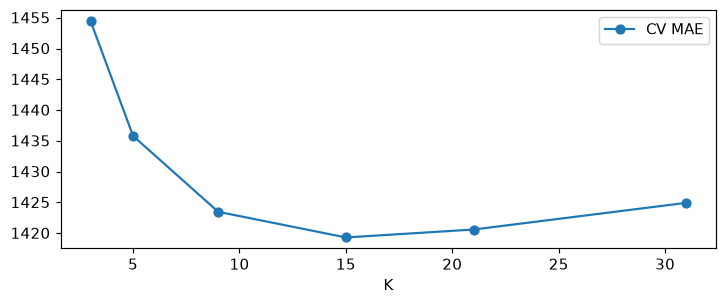

In [11]:
tune_model('KNN', {'kneighborsregressor__n_neighbors': [3, 5, 9, 15, 21, 31]})
search = searches['KNN']
k_scores = pd.DataFrame({'K': search.cv_results_['param_kneighborsregressor__n_neighbors'],
                         'CV MAE': -search.cv_results_['mean_test_score']})
display(k_scores)
k_scores.plot(x='K', y='CV MAE', marker='o', figsize=(7, 3))
plt.tight_layout()
plt.show()


### Cây và rừng
Chạy tìm tham số cho cả hai. Rừng giữ 60 cây để thời gian chạy vừa phải.


In [12]:
tune_model('Decision Tree', {'max_depth': [6, 12, 18, None], 'min_samples_leaf': [5, 20]})
tune_model('Random Forest', {'max_depth': [10, 18, None], 'min_samples_leaf': [2, 10]})


Decision Tree | Tham số: {'max_depth': None, 'min_samples_leaf': 5} | CV MAE: 1003.3244853515747 | Validation MAE: 1013.981610589873
Random Forest | Tham số: {'max_depth': 18, 'min_samples_leaf': 2} | CV MAE: 769.884644123943 | Validation MAE: 910.66172763463


### PCA và MLP
PCA và bộ chuẩn hóa được học lại trong mỗi lượt CV.
Với MLP, regressor__mlpregressor đi vào mạng bên trong bộ chuẩn hóa đáp án; hidden_layer_sizes là số nút ở từng lớp ẩn.
MLP không dùng early stopping với phép chia ngẫu nhiên. Shuffle=False giữ thứ tự các mẫu khi học.


In [13]:
tune_model('PCA + Ridge', {'pca__n_components': [0.90, 0.95, 0.99, 0.999], 'ridge__alpha': [0.1, 10]})
tune_model('MLP', {'regressor__mlpregressor__hidden_layer_sizes': [(32,), (32, 16)],
                   'regressor__mlpregressor__alpha': [0.001, 0.1]})
tuning_results = pd.DataFrame(tuning_rows, columns=['Model', 'Tham số chọn', 'CV MAE', 'Validation MAE'])
display(tuning_results)


PCA + Ridge | Tham số: {'pca__n_components': 0.999, 'ridge__alpha': 0.1} | CV MAE: 361.2396517242064 | Validation MAE: 290.6022481980934
MLP | Tham số: {'regressor__mlpregressor__alpha': 0.1, 'regressor__mlpregressor__hidden_layer_sizes': (32, 16)} | CV MAE: 341.98977173672296 | Validation MAE: 413.6241689224353


,Model,Tham số chọn,CV MAE,Validation MAE
0,Ridge,{'ridge__alpha': 0.001},185.9197,163.7004
1,Lasso,{'lasso__alpha': 0.1},195.9828,183.3297
2,KNN,{'kneighborsregressor__n_neighbors': 15},"1,419.2993","1,837.1900"
3,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 5}","1,003.3245","1,013.9816"
4,Random Forest,"{'max_depth': 18, 'min_samples_leaf': 2}",769.8846,910.6617
5,PCA + Ridge,"{'pca__n_components': 0.999, 'ridge__alpha': 0.1}",361.2397,290.6022
6,MLP,"{'regressor__mlpregressor__alpha': 0.1, 'regre...",341.9898,413.6242


## 7. Thử hai hướng tối ưu thêm
Giữ nguyên các dòng train/validation và Linear 49 đầu vào làm mốc.
Chỉ chọn phương án bằng train/validation. Test đã được chấm ở phiên trước và không dùng để quyết định vòng thử này.


### Hướng 2 — Thử bỏ từng nhóm đầu vào
So 8 cách bằng cùng Linear, cùng CV và cùng thời điểm. Bỏ từng nhóm và thử thêm một tập gọn để đối chiếu.
Chỉ đưa cách giảm biến vào nhóm ứng viên nếu cả CV MAE và validation MAE cùng thấp hơn bản 49 biến.
Đây là quy tắc lựa chọn thực dụng, không phải kiểm định ý nghĩa thống kê. Giảm rất ít trên một bảng chưa đủ kết luận tốt hơn.


In [14]:
removals = {
    'Bỏ thời tiết': weather,
    'Bỏ độ lệch chuẩn': [c for c in selected_columns if '_std_' in c],
    'Bỏ trung bình': [c for c in selected_columns if '_mean_' in c],
    'Bỏ cả nhóm rolling': [c for c in selected_columns if '_std_' in c or '_mean_' in c],
    'Bỏ lag 3/6/18': [f'{z}_lag_{lag}' for z in zones for lag in [3, 6, 18]],
    'Bỏ lịch sử tuần': [c for c in selected_columns if '_weekly_' in c]
}
ablation_columns = {'Giữ nguyên': selected_columns}
for name, removed in removals.items():
    ablation_columns[name] = [c for c in selected_columns if c not in removed]
compact = zones + [f'{z}_lag_{lag}' for z in zones for lag in [1, 3]]
compact += [c for c in selected_columns if '_mean_' in c]
compact += ['clock_sin', 'clock_cos', 'weekday_sin', 'weekday_cos', 'is_weekend']
compact += [f'{z}_daily_reference' for z in zones] + [f'{z}_weekly_reference' for z in zones]
ablation_columns['Tập gọn'] = compact
feature_models, feature_predictions, feature_rows = {}, {}, []
for name, columns in ablation_columns.items():
    model = make_pipeline(StandardScaler(), LinearRegression())
    cv_errors = -cross_val_score(model, X_train_all[columns], y_train,
                                 scoring='neg_mean_absolute_error', cv=cv, error_score='raise')
    model.fit(X_train_all[columns], y_train)
    predicted = model.predict(X_val_all[columns])
    feature_models[name], feature_predictions[name] = model, predicted
    feature_rows.append([name, len(columns), cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])
feature_ablation = pd.DataFrame(feature_rows, columns=['Phương án', 'Số biến', 'CV MAE', 'CV độ lệch chuẩn'] + metric_names).set_index('Phương án')
display(feature_ablation)
reference = feature_ablation.loc['Giữ nguyên']
approved_features = feature_ablation[(feature_ablation['CV MAE'] < reference['CV MAE']) & (feature_ablation.MAE < reference.MAE)]
extra_models, extra_columns = {}, {}
for name in approved_features.index:
    label = 'Linear - ' + name
    extra_models[label], extra_columns[label] = feature_models[name], ablation_columns[name]
    val_predictions[label] = feature_predictions[name]
print('Cách giảm biến đạt cả hai tiêu chí:', approved_features.index.tolist())


Cách giảm biến đạt cả hai tiêu chí: []


,Số biến,CV MAE,CV độ lệch chuẩn,MAE,RMSE,MAPE (%),R2
Phương án,,,,,,,
Giữ nguyên,49,185.9190,14.7062,163.7002,248.1691,0.7952,0.9972
Bỏ thời tiết,44,186.1875,15.3739,163.6213,248.1589,0.7950,0.9972
Bỏ độ lệch chuẩn,43,184.4486,12.1606,163.9602,249.1129,0.7950,0.9971
Bỏ trung bình,43,185.8556,14.7267,163.8047,248.2614,0.7955,0.9972
Bỏ cả nhóm rolling,37,184.4378,12.1992,164.1016,249.2103,0.7954,0.9971
Bỏ lag 3/6/18,40,184.7321,13.1491,164.1011,248.7772,0.7972,0.9971
Bỏ lịch sử tuần,43,190.5180,15.0224,166.3398,250.6944,0.8131,0.9971
Tập gọn,26,242.1579,41.5777,192.7679,290.6699,0.9285,0.9962


### Hướng 1 — Học mức tăng/giảm điện
Đáp án mới = điện ở bước kế tiếp − điện hiện tại. Khi dự đoán xong, cộng lại điện hiện tại để được số điện thật cần dự báo.
Clone hai mô hình RF/MLP đã tìm tham số ở phần 6 rồi học lại với đáp án mới; không dùng lại bộ chuẩn hóa đáp án cũ của MLP.
Giữ tham số để so tác động của việc đổi đáp án; chưa gọi chúng là tham số tối ưu cho bài toán delta.
MAE trên delta bằng MAE sau khi cộng lại cùng số điện hiện tại. Không cắt các mức giảm âm.


In [15]:
delta_train = y_train.to_numpy() - X_train_all[zones].to_numpy()
delta_names, delta_rows = set(), []
for name in ['Random Forest', 'MLP']:
    model = clone(tuned[name])
    cv_errors = -cross_val_score(model, X_train, delta_train, scoring='neg_mean_absolute_error',
                                 cv=cv, n_jobs=1, error_score='raise')
    model.fit(X_train, delta_train)
    label = name + ' (delta)'
    predicted = X_val_all[zones].to_numpy() + model.predict(X_val)
    extra_models[label], extra_columns[label] = model, selected_columns
    delta_names.add(label)
    val_predictions[label] = predicted
    before_mae = mean_absolute_error(y_val, val_predictions[name + ' (tuned)'])
    delta_rows.append([label, before_mae, cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])
delta_results = pd.DataFrame(delta_rows, columns=['Model', 'Validation MAE trước', 'CV MAE delta', 'CV độ lệch chuẩn'] + metric_names).set_index('Model')
display(delta_results)


,Validation MAE trước,CV MAE delta,CV độ lệch chuẩn,MAE,RMSE,MAPE (%),R2
Model,,,,,,,
Random Forest (delta),910.6617,256.6403,60.2178,196.3589,306.5373,0.9482,0.9959
MLP (delta),413.6242,228.3822,40.5117,172.0831,257.3164,0.8299,0.9970


## 8. Chốt mô hình bằng validation
Giữ cả mô hình ban đầu và bản tối ưu. Bản tối ưu theo CV có thể vẫn kém hơn trên validation.
Chọn mô hình có MAE validation nhỏ nhất trước khi mở test; kể cả cách đoán đơn giản cũng được xét.


In [16]:
candidates = models.copy()
for name, model in tuned.items():
    candidates[name + ' (tuned)'] = model
candidates.update(extra_models)
candidate_columns = {name: selected_columns for name in candidates}
candidate_columns.update(extra_columns)

def predict_candidate(name, inputs):
    predicted = candidates[name].predict(inputs[candidate_columns[name]])
    if name in delta_names:
        predicted = inputs[zones].to_numpy() + predicted
    return predicted

validation_rows = [[name, *metrics(y_val, predicted)] for name, predicted in val_predictions.items()]
validation_results = pd.DataFrame(validation_rows, columns=['Model'] + metric_names).set_index('Model').sort_values('MAE')
best_name = validation_results.index[0]
display(validation_results)
print('Đã chốt trước test:', best_name)


Đã chốt trước test: Linear


,MAE,RMSE,MAPE (%),R2
Model,,,,
Linear,163.7002,248.1691,0.7952,0.9972
Ridge (tuned),163.7004,248.1694,0.7952,0.9972
MLP (delta),172.0831,257.3164,0.8299,0.9970
Lasso (tuned),183.3297,277.2246,0.9283,0.9958
Random Forest (delta),196.3589,306.5373,0.9482,0.9959
Ridge,210.9964,313.5944,1.0269,0.9954
Lasso,223.5357,346.3221,1.0648,0.9948
PCA + Ridge (tuned),290.6022,421.0584,1.4329,0.9910
Persistence,295.4928,463.5863,1.3623,0.9910


## 9. Xem một dự đoán thật
Lấy thời điểm đầu validation. Xem điện hiện tại, dự đoán bước kế tiếp, số thật và độ lệch ở từng khu vực.
Sai số của một thời điểm khác với MAE của cả tập.


In [17]:
example = pd.DataFrame({'Hiện tại': X_val_all[zones].iloc[0],
                        'Thực tế sau 10 phút': y_val.iloc[0],
                        'Dự đoán': val_predictions[best_name][0]})
example['Sai số tuyệt đối'] = (example['Thực tế sau 10 phút'] - example['Dự đoán']).abs()
print('Lúc dự đoán:', origin[validation].iloc[0], '| Lúc đáp án:', target_time[validation].iloc[0])
display(example)
print('MAE của riêng thời điểm này:', example['Sai số tuyệt đối'].mean())


Lúc dự đoán: 2017-09-12 19:10:00 | Lúc đáp án: 2017-09-12 19:20:00
MAE của riêng thời điểm này: 188.6988431684343


,Hiện tại,Thực tế sau 10 phút,Dự đoán,Sai số tuyệt đối
zone_1,"47,322.4779","47,736.6372","47,446.1049",290.5322
zone_2,"28,466.9439","28,740.1247","28,524.0353",216.0894
zone_3,"21,869.1726","21,875.0562","21,934.5310",59.4749


## 10. Đánh giá cuối trên train và test
Sau khi đã chốt cách làm, mở test và chấm toàn bộ mô hình để đối chiếu. Không đổi tham số theo điểm test.
MAE là độ lệch trung bình theo đơn vị điện gốc; dùng chính để chọn tham số.
RMSE nhạy với lỗi lớn; MAPE là phần trăm sai số; R² gần 1 thường tốt hơn và không phải phần trăm chính xác.
MAE/RMSE/MAPE tính chung 3 khu vực; R² lấy trung bình điểm từng khu vực.

Đánh giá cuốn chiếu: tại mỗi mốc, dùng số đo đã có để đoán mốc tiếp theo.
Lấy thêm 32 ngày lịch sử trước test để tạo đủ đầu vào tháng. Không học lại mô hình, scaler hay PCA bằng test.
Điểm train KNN có thể bằng 0 vì gặp lại đúng mẫu đã học.


In [18]:
test.columns = df.columns
test['time'] = pd.to_datetime(test['time'], format='%m/%d/%Y %H:%M')
assert test.time.diff().dropna().eq(time_step).all()
assert test.time.iloc[0] - df.time.iloc[-1] == time_step
assert test.notna().all().all() and np.isfinite(test[weather + zones]).all().all()
test_history = pd.concat([df.tail(32 * steps_per_day), test])
X_test_all, y_test, test_origin, test_target_time = make_features(test_history)
in_test = test_origin >= test.time.iloc[0]
X_test_all, y_test = X_test_all.loc[in_test], y_test.loc[in_test]
test_origin, test_target_time = test_origin.loc[in_test], test_target_time.loc[in_test]
X_test = X_test_all[selected_columns]
assert target_time[validation].max() < test_origin.min()
train_predictions = {name: X_train_all[columns].to_numpy() for name, columns in baseline_columns.items()}
test_predictions = {name: X_test_all[columns].to_numpy() for name, columns in baseline_columns.items()}
for name in candidates:
    train_predictions[name] = predict_candidate(name, X_train_all)
    test_predictions[name] = predict_candidate(name, X_test_all)
metric_rows = []
for name in val_predictions:
    metric_rows.append([name, *metrics(y_train, train_predictions[name]), *metrics(y_test, test_predictions[name])])
columns = ['Model'] + ['Train ' + m for m in metric_names] + ['Test ' + m for m in metric_names]
train_test_results = pd.DataFrame(metric_rows, columns=columns).set_index('Model')
display(train_test_results)
best_test_prediction = test_predictions[best_name]
print('Mô hình đã chốt:', best_name, '| Số dòng test:', len(y_test))
display(train_test_results.loc[[best_name]])


Mô hình đã chốt: Linear | Số dòng test: 7862


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Persistence,348.0153,523.9934,1.4638,0.9934,293.1130,456.7377,1.4608,0.9915
Previous day,"1,137.5372","1,769.7652",4.8791,0.9150,951.8637,"1,528.6008",4.8648,0.8949
Previous week,"1,486.2506","2,230.1941",6.2850,0.8728,"1,053.2395","1,641.1452",6.1375,0.8249
Previous month,"3,075.5856","4,409.2883",13.0812,0.4976,"2,215.2345","3,010.3732",11.7836,0.5977
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967
Ridge,212.8458,331.6777,0.9173,0.9973,255.5105,366.1971,1.3066,0.9940
Lasso,238.4464,375.9571,1.0164,0.9965,277.6832,391.2877,1.3941,0.9937
KNN,0.0002,0.0004,0.0000,1.0000,"3,213.8866","3,646.0513",18.8797,0.2541
Decision Tree,385.4110,549.3070,1.6597,0.9922,"2,176.6558","3,067.6209",12.4191,0.5937


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967


## 11. Sai số theo thời gian
Mỗi sai số được gắn với lúc có đáp án, không phải lúc bắt đầu dự đoán.
Bảng tuần/tháng so Persistence và 3 mô hình tốt nhất trên validation. File CSV giữ tất cả mô hình.
Mỗi ô là MAE của các dự đoán trong khoảng đó, tính chung cả 3 khu vực; tuần đầu/cuối có thể chưa đủ 7 ngày.


In [19]:
row_errors = {name: np.abs(y_test.to_numpy() - predicted).mean(axis=1)
              for name, predicted in test_predictions.items()}
errors_by_time = pd.DataFrame(row_errors, index=pd.DatetimeIndex(test_target_time, name='Thời điểm đáp án'))
weekly_mae = errors_by_time.groupby(errors_by_time.index.to_period('W')).mean()
monthly_mae = errors_by_time.groupby(errors_by_time.index.to_period('M')).mean()
show_models = list(dict.fromkeys(['Persistence'] + validation_results.index[:3].tolist()))
print('MAE theo tuần:')
display(weekly_mae[show_models])
print('MAE theo tháng:')
display(monthly_mae[show_models])
plot_zone = 'zone_1'  # Có thể đổi zone_2 hoặc zone_3.
zone_index = zones.index(plot_zone)
timeline = pd.DataFrame({'Lúc dự đoán': test_origin.to_numpy(), 'Lúc đáp án': test_target_time.to_numpy(),
                         'Thực tế': y_test[plot_zone].to_numpy(), 'Dự đoán': best_test_prediction[:, zone_index]})
timeline['Sai số tuyệt đối'] = (timeline['Thực tế'] - timeline['Dự đoán']).abs()
display(timeline.head(12))


MAE theo tuần:
MAE theo tháng:


,Persistence,Linear,Ridge (tuned),MLP (delta)
Thời điểm đáp án,,,,
2017-11-06/2017-11-12,304.2645,190.4812,190.4822,230.3459
2017-11-13/2017-11-19,316.8090,194.3530,194.3538,222.4360
2017-11-20/2017-11-26,295.0123,177.8240,177.8245,216.4102
2017-11-27/2017-12-03,277.2971,159.0940,159.0949,211.5337
2017-12-04/2017-12-10,281.6906,158.2579,158.2588,209.8802
2017-12-11/2017-12-17,301.1143,187.4947,187.4956,234.7789
2017-12-18/2017-12-24,280.9410,157.8260,157.8272,211.7756
2017-12-25/2017-12-31,287.6341,162.2850,162.2860,216.3274


,Persistence,Linear,Ridge (tuned),MLP (delta)
Thời điểm đáp án,,,,
2017-11,302.4148,184.9023,184.9030,221.7492
2017-12,285.4864,164.2074,164.2084,217.0298


,Lúc dự đoán,Lúc đáp án,Thực tế,Dự đoán,Sai số tuyệt đối
0,2017-11-06 09:30:00,2017-11-06 09:40:00,"25,741.5385","25,638.2693",103.2692
1,2017-11-06 09:40:00,2017-11-06 09:50:00,"26,529.2308","26,367.2490",161.9817
2,2017-11-06 09:50:00,2017-11-06 10:00:00,"27,200.0000","27,089.0567",110.9433
3,2017-11-06 10:00:00,2017-11-06 10:10:00,"27,489.2308","27,759.5101",270.2793
4,2017-11-06 10:10:00,2017-11-06 10:20:00,"28,135.3846","28,034.7354",100.6492
5,2017-11-06 10:20:00,2017-11-06 10:30:00,"29,070.7692","28,643.4740",427.2952
6,2017-11-06 10:30:00,2017-11-06 10:40:00,"29,495.3846","29,689.3753",193.9907
7,2017-11-06 10:40:00,2017-11-06 10:50:00,"29,513.8462","29,936.9133",423.0671
8,2017-11-06 10:50:00,2017-11-06 11:00:00,"29,920.0000","29,745.8127",174.1873
9,2017-11-06 11:00:00,2017-11-06 11:10:00,"30,387.6923","30,336.1620",51.5303


## 12. Biểu đồ hai đường: thực tế và dự đoán
Hiện 7 ngày đầu test để nhìn rõ từng lần tăng/giảm. Bảng điểm vẫn tính trên toàn bộ test.
Đổi plot_zone ở phần 11 nếu muốn xem khu vực khác. Hai đường dùng cùng thời điểm đáp án.


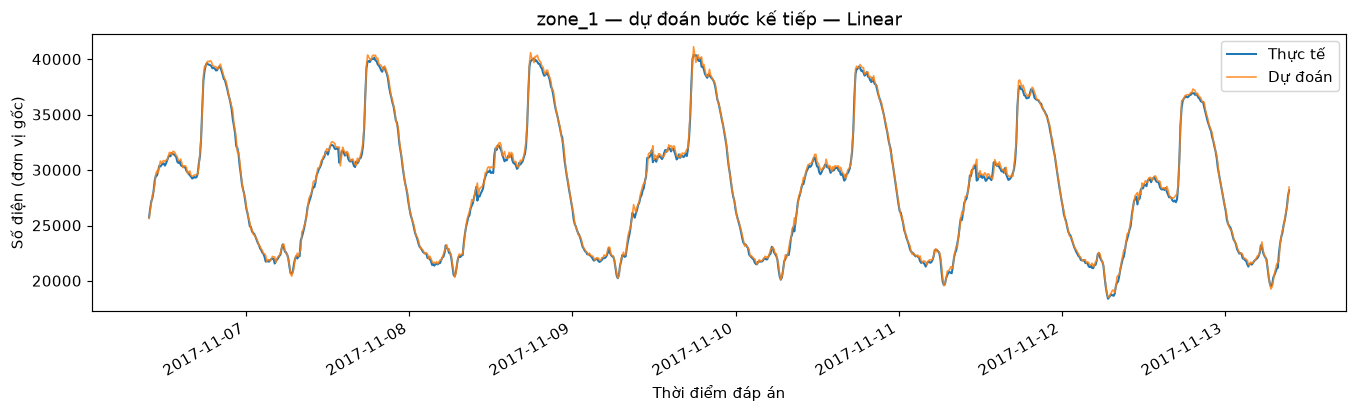

In [20]:
shown = timeline[timeline['Lúc đáp án'] < timeline['Lúc đáp án'].iloc[0] + pd.Timedelta(days=7)]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(shown['Lúc đáp án'], shown['Thực tế'], label='Thực tế', linewidth=1.4)
ax.plot(shown['Lúc đáp án'], shown['Dự đoán'], label='Dự đoán', linewidth=1.1, alpha=0.85)
ax.set(title=f'{plot_zone} — dự đoán bước kế tiếp — {best_name}', xlabel='Thời điểm đáp án', ylabel='Số điện (đơn vị gốc)')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('next_step_forecast.png', dpi=160)
plt.show()


## 13. Lưu kết quả và kết luận
CSV và ảnh nằm trong máy Colab sau khi chạy. Các số dưới đây được tính mới từ dữ liệu.
Thêm mạng nơ-ron, PCA hay chu kỳ tháng không bảo đảm tốt hơn; kết luận theo kết quả đã chạy.


In [21]:
feature_ablation.to_csv('feature_ablation_comparison.csv')
delta_results.to_csv('delta_target_comparison.csv')
seasonality.to_csv('seasonality_comparison.csv', index=False)
validation_results.to_csv('validation_model_comparison.csv')
tuning_results.to_csv('tuning_comparison.csv', index=False)
train_test_results.to_csv('train_test_model_comparison.csv')
weekly_mae.to_csv('mae_by_week.csv')
monthly_mae.to_csv('mae_by_month.csv')
forecast_table = pd.DataFrame({'origin': test_origin.to_numpy(), 'target_time': test_target_time.to_numpy()})
for i, zone in enumerate(zones):
    forecast_table[zone + '_actual'] = y_test[zone].to_numpy()
    forecast_table[zone + '_predicted'] = best_test_prediction[:, i]
    forecast_table[zone + '_absolute_error'] = np.abs(y_test[zone].to_numpy() - best_test_prediction[:, i])
forecast_table.to_csv('next_step_predictions.csv', index=False)
print('Chu kỳ được chọn:', selected_group, '| Mô hình được chọn trên validation:', best_name)
print('MAE validation:', validation_results.loc[best_name, 'MAE'])
print('MAE test:', train_test_results.loc[best_name, 'Test MAE'])
print('Đã lưu 9 bảng CSV và ảnh next_step_forecast.png.')


Chu kỳ được chọn: + Tuần | Mô hình được chọn trên validation: Linear
MAE validation: 163.7002081309757
MAE test: 173.53089669485598
Đã lưu 9 bảng CSV và ảnh next_step_forecast.png.


### Phạm vi và nguồn
Đã học xong nên không để phần chờ chương 11–15. Bài dùng các mô hình phù hợp với hồi quy số điện.
MLP theo chương 11; PCA theo chương 14; cách đánh giá theo chương 13. Phân cụm chương 12 không trực tiếp dự đoán giá trị điện.
Không sử dụng hai phần cảnh báo và xử lý đầu vào lỗi của bản cũ.

Dữ liệu chỉ có năm 2017 ở Tetouan; không suy ra kết quả cho doanh nghiệp khác hay các năm sau.
Train/validation phục vụ phát triển; test chỉ chấm sau khi chốt. Test đã được chấm ở các phiên bản 30 phút và 10 phút trước. Vòng thử delta/lọc biến chỉ dùng train/validation để quyết định; điểm test ở đây là đối chiếu trên tập cũ, không phải một tập kiểm chứng hoàn toàn mới.
Cần thống nhất cách chia với nhóm dùng chung dữ liệu theo yêu cầu lớp; tỷ lệ hiện dùng là 70/15/15 theo thời gian.

Nguồn: [UCI Tetouan](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city),
[yêu cầu môn học](https://docs.google.com/spreadsheets/d/17AhxqqU-uAUvH9RTIqbgO1w13_obfjTln45ukoH7SmM/edit),
[GitHub nhóm](https://github.com/huy1907ddddddd/DS66B_group_14).
